# Task 3 - Frozen ImageNet backbone: Xception and ResNet-50

Recipe from the `transfer-learning` branch, protocol of `src/training/xception_aspect_frozen.py` (the run that
introduced this data pipeline), now applied to both backbones: the ImageNet backbone is frozen and
global-average pooled, and only a head is trained:

`features -> Dropout(0.45) -> Dense(512, ReLU) -> BatchNorm -> Dropout(0.2) -> Dense(4, softmax)`

AdamW (lr 5e-4, weight decay 1e-4), cross-entropy, batch 32, up to 30 epochs, ReduceLROnPlateau on val_loss
(x0.5, patience 2), early stopping after 6 epochs without a better val macro F1, best epoch by val macro F1.
Inputs are scaled the way each checkpoint was trained: [-1, 1] for Xception, caffe BGR mean subtraction for
ResNet-50.

Differences from the branch, both forced by moving every task to one framework (Keras):

- The branch ran PyTorch. Xception here is the Keras ImageNet checkpoint, the same weights timm's
  `legacy_xception` was converted from. ResNet-50 is the Keras ImageNet checkpoint (the original caffe
  weights, about 75% ImageNet top-1), not torchvision's `ResNet50_Weights.DEFAULT` (about 81%).
- The branch cached one augmented view of the training features per run. Here the frozen backbone runs on
  freshly augmented images every epoch.

**Data.** Same pipeline as every other task (`src/data.py`, the transfer-learning branch protocol): `data/split_aspect.csv` (Kaggle test kept; Kaggle train+val re-split 800/200 per class, stratified by aspect group), square crop from the raw image (random on train, center on val/test) resized to 224x224, train-only affine/flip/brightness/contrast augmentation, and aspect-balanced sampling. Batches arrive as [0, 255] pixels; the model rescales them itself. The best epoch is picked on validation; test is predicted once at the end.

In [1]:
import sys
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "config.py").exists())
sys.path.insert(0, str(ROOT))

import keras
import pandas as pd
from keras import layers

import config
from src import data, experiment

experiment.setup()
frames, datasets = data.load_datasets()
{split: len(frame) for split, frame in frames.items()}

I0000 00:00:1791568867.368110   42595 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1791568867.412238   42595 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


I0000 00:00:1791568868.481860   42595 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')] | policy: float32


I0000 00:00:1791568869.966694   42595 gpu_device.cc:2043] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 3618 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 3050 6GB Laptop GPU, pci bus id: 0000:01:00.0, compute capability: 8.6


{'train': 3200, 'val': 800, 'test': 800}

In [2]:
def build_frozen(name):
    base, preprocess = experiment.backbone(name)
    inputs = keras.Input((config.IMAGE_SIZE, config.IMAGE_SIZE, 3))
    x = base(preprocess(inputs), training=False)
    x = layers.Dropout(0.45)(x)
    x = layers.Dense(512, activation="relu")(x)
    x = layers.BatchNormalization(momentum=0.9, epsilon=1e-5)(x)   # PyTorch BatchNorm1d defaults
    x = layers.Dropout(0.2)(x)
    outputs = layers.Dense(len(config.CLASS_NAMES), activation="softmax")(x)
    return keras.Model(inputs, outputs, name=f"frozen_{name}")


settings = {"source": "transfer-learning branch, xception_aspect_frozen.py protocol",
            "head": "Dropout 0.45 - Dense 512 ReLU - BatchNorm - Dropout 0.2 - Dense 4",
            "optimizer": "AdamW 5e-4, weight decay 1e-4", "loss": "categorical cross-entropy", "epochs": 30,
            "early_stopping": "val macro F1, patience 6", "reduce_lr": "val_loss x0.5, patience 2",
            "selection": "val macro F1"}

## Train and evaluate both backbones

=== frozen_xception: 1,052,164 trainable parameters
Epoch 1/30


I0000 00:00:1791568872.107672   42595 generator_dataset_op.cc:213] Memory patch applied: M_TRIM_THRESHOLD=128 kb was set.


I0000 00:00:1791568876.801658   42667 cuda_dnn.cc:461] Loaded cuDNN version 92000


/home/minhquang/miniconda3/envs/dl/lib/python3.11/site-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


100/100 - 26s - 264ms/step - accuracy: 0.7053 - f1: 0.6984 - loss: 0.8436 - val_accuracy: 0.8000 - val_f1: 0.8005 - val_loss: 0.5349 - learning_rate: 5.0000e-04


...

100/100 - 17s - 170ms/step - accuracy: 0.8559 - f1: 0.8527 - loss: 0.3735 - val_accuracy: 0.8963 - val_f1: 0.8955 - val_loss: 0.2605 - learning_rate: 1.2500e-04


Epoch 20/30


100/100 - 19s - 186ms/step - accuracy: 0.8712 - f1: 0.8669 - loss: 0.3442 - val_accuracy: 0.8850 - val_f1: 0.8850 - val_loss: 0.2655 - learning_rate: 1.2500e-04


Epoch 21/30


100/100 - 17s - 169ms/step - accuracy: 0.8622 - f1: 0.8573 - loss: 0.3495 - val_accuracy: 0.8938 - val_f1: 0.8941 - val_loss: 0.2771 - learning_rate: 1.2500e-04


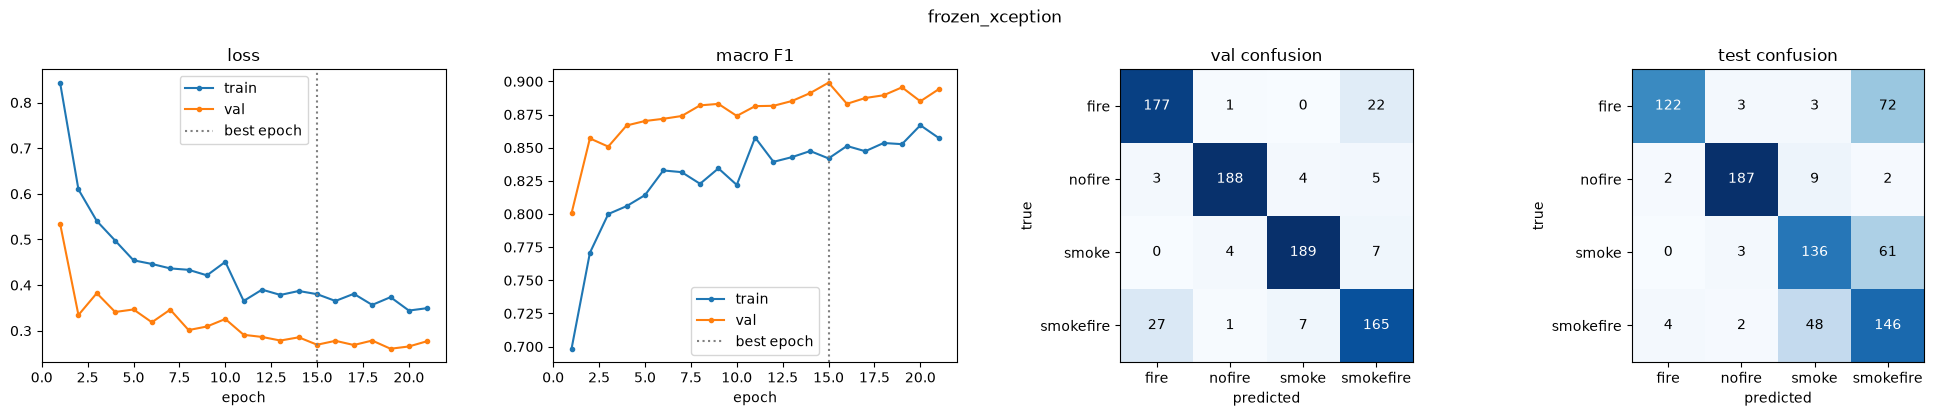

=== frozen_resnet50: 1,052,164 trainable parameters
Epoch 1/30


/home/minhquang/miniconda3/envs/dl/lib/python3.11/site-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


100/100 - 27s - 266ms/step - accuracy: 0.7519 - f1: 0.7474 - loss: 0.6909 - val_accuracy: 0.8850 - val_f1: 0.8839 - val_loss: 0.3181 - learning_rate: 5.0000e-04


Epoch 2/30


100/100 - 20s - 199ms/step - accuracy: 0.8444 - f1: 0.8405 - loss: 0.4332 - val_accuracy: 0.8863 - val_f1: 0.8871 - val_loss: 0.2977 - learning_rate: 5.0000e-04


...

100/100 - 19s - 189ms/step - accuracy: 0.9091 - f1: 0.9058 - loss: 0.2283 - val_accuracy: 0.9388 - val_f1: 0.9388 - val_loss: 0.1407 - learning_rate: 2.5000e-04


Epoch 16/30


100/100 - 20s - 196ms/step - accuracy: 0.9209 - f1: 0.9170 - loss: 0.2067 - val_accuracy: 0.9413 - val_f1: 0.9412 - val_loss: 0.1401 - learning_rate: 2.5000e-04


Epoch 17/30


100/100 - 17s - 173ms/step - accuracy: 0.9300 - f1: 0.9250 - loss: 0.1842 - val_accuracy: 0.9388 - val_f1: 0.9387 - val_loss: 0.1439 - learning_rate: 2.5000e-04


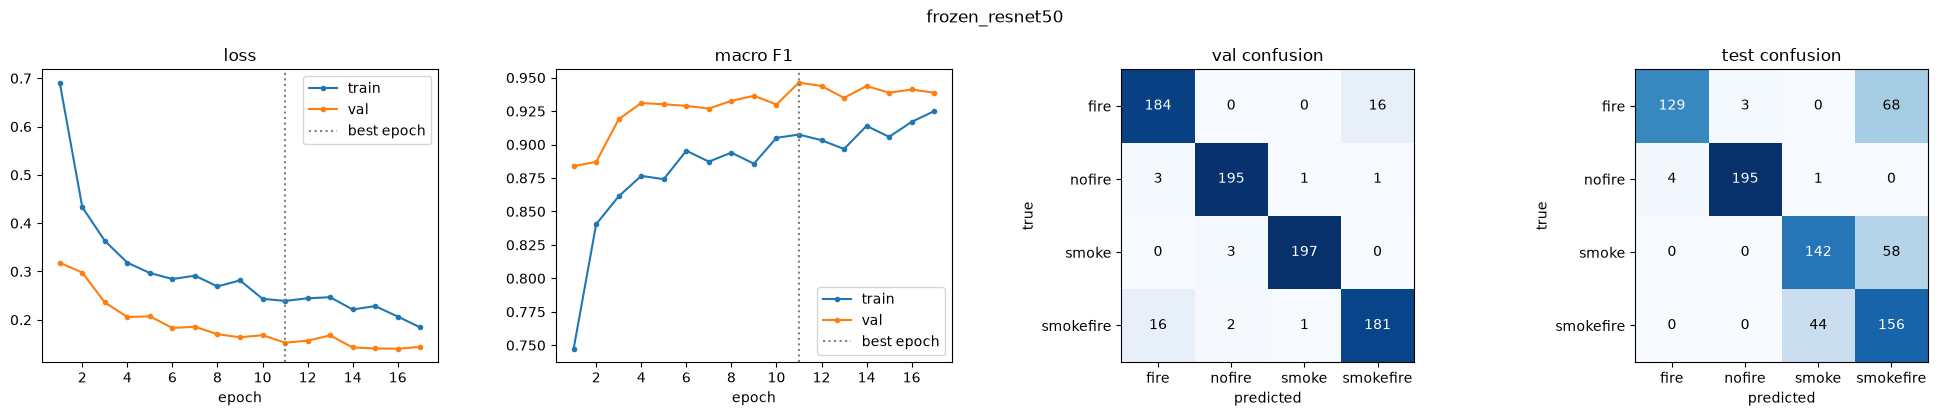

,task,run,trainable_params,total_params,best_epoch,epochs_run,train_minutes,val_acc,val_f1,test_acc,test_f1,test_f1_fire,test_f1_nofire,test_f1_smoke,test_f1_smokefire,test_smokefire_as_smoke,test_fire_as_smokefire,test_fire_or_smokefire_as_nofire
0,3 frozen backbone,frozen_xception,1052164,21914668,15,21,6.7,0.89875,0.899040,0.73875,0.746169,0.743902,0.946835,0.686869,0.607069,48,72,5
1,3 frozen backbone,frozen_resnet50,1052164,24640900,11,17,5.6,0.94625,0.946292,0.77750,0.783957,0.774775,0.979899,0.733850,0.647303,44,68,3


In [3]:
rows = []
for name in experiment.BACKBONES:
    keras.backend.clear_session()
    keras.utils.set_random_seed(config.RANDOM_SEED)
    model = build_frozen(name)
    experiment.compile_model(model, keras.optimizers.AdamW(5e-4, weight_decay=1e-4))
    run = f"frozen_{name}"
    print(f"=== {run}: {experiment.count_params(model)[1]:,} trainable parameters")
    fit_info = experiment.fit(model, run, datasets, epochs=30, monitor="val_f1", early_stopping=6,
                              reduce_lr=dict(factor=0.5, patience=2))
    rows.append(experiment.evaluate(model, run, "3 frozen backbone", frames, datasets, fit_info,
                                    {**settings, "backbone": name}))
pd.DataFrame(rows)

## All runs so far

In [4]:
board = pd.read_csv(config.RESULTS_DIR / "leaderboard.csv")
board[["task", "run", "trainable_params", "best_epoch", "val_acc", "val_f1", "test_acc", "test_f1",
       "test_f1_smokefire", "test_smokefire_as_smoke", "test_fire_as_smokefire"]].round(4)

,task,run,trainable_params,best_epoch,val_acc,val_f1,test_acc,test_f1,test_f1_smokefire,test_smokefire_as_smoke,test_fire_as_smokefire
0,1 basic NN,basic_nn,3147012,28,0.6863,0.6792,0.6050,0.6088,0.4637,107,50
1,2 custom CNN,custom_cnn,2738340,46,0.9563,0.9564,0.7625,0.7648,0.6845,19,72
2,3 frozen backbone,frozen_xception,1052164,15,0.8988,0.8990,0.7388,0.7462,0.6071,48,72
3,3 frozen backbone,frozen_resnet50,1052164,11,0.9463,0.9463,0.7775,0.7840,0.6473,44,68
